# Project 07 — 09 — Candidate Net Validation (V1 vs DD Only vs Combined DD+Vol)

Apples-to-apples validation of the three candidates on **identical gross and net-of-cost** assumptions. Reuses `src/statistics/` (no formulas duplicated here). **NB05 remains the PSR/DSR/MinTRL methodology notebook — its conclusions are unchanged.** No winner is selected here.

## 1. Setup & inputs

Net daily return series were reconstructed from the Project 06 tournament per-candidate `equity_curve.csv` + `turnover.csv` (cost model `net_t = gross_t − turnover_t·(bps/10000)`, canonical **10 bps** one-way) and persisted to `experiments/completed/exp_007_candidate_net_validation/`. Gross & net Sharpe reproduce each candidate's `metrics.json` to 1e-4.

In [1]:
from pathlib import Path
import sys, json, math
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils.metrics import sharpe_ratio
from src.statistics.bootstrap import bootstrap_metric, bootstrap_confidence_interval
from src.statistics.permutation import permutation_p_value
from src.statistics.deflated_sharpe import (probabilistic_sharpe_ratio, deflated_sharpe_ratio,
                                            minimum_track_record_length)

EXP07 = PROJECT_ROOT / "experiments/completed/exp_007_candidate_net_validation"
FILES = {"V1": "v1_daily_returns.csv", "DD Only": "dd_only_daily_returns.csv",
         "Combined DD+Vol": "combined_dd_vol_daily_returns.csv"}
data = {name: pd.read_csv(EXP07 / f, parse_dates=["date"]).set_index("date") for name, f in FILES.items()}

# shared config (identical to NB05 methodology)
SEED, N_BOOT, BLOCK, PPY = 20260820, 10000, 20, 252
V_TRIALS = 4.920e-4                 # per-period trial-Sharpe variance (NB05 trial universe)
N_SCENARIOS = [2, 5, 100]
DSR_HURDLE_PP = 0.05613            # conservative (N=100) per-period SR* from NB05
for name, df in data.items():
    print(f"{name:16} obs={len(df)} cols={list(df.columns)}")

V1               obs=2558 cols=['gross_return', 'turnover', 'exposure', 'cost_drag', 'net_return']
DD Only          obs=2558 cols=['gross_return', 'turnover', 'exposure', 'cost_drag', 'net_return']
Combined DD+Vol  obs=2558 cols=['gross_return', 'turnover', 'exposure', 'cost_drag', 'net_return']


## 2. Gross vs net economic comparison

In [2]:
def econ(r, ppy=PPY):
    r = pd.Series(r).dropna()
    eq = (1 + r).cumprod(); mdd = float((eq/eq.cummax()-1).min())
    cagr = float(eq.iloc[-1] ** (ppy/len(r)) - 1)
    return {"Ann Sharpe": sharpe_ratio(r), "Ann Vol": float(r.std(ddof=1)*np.sqrt(ppy)),
            "CAGR": cagr, "MDD": mdd, "Calmar": cagr/abs(mdd)}

rows=[]
for name, df in data.items():
    g, n = econ(df["gross_return"]), econ(df["net_return"])
    rows.append({"candidate":name, "basis":"gross", **g,
                 "mean turnover": float(df["turnover"].mean()),
                 "ann cost drag": float(df["cost_drag"].mean()*PPY),
                 "cum cost drag": float(df["cost_drag"].sum())})
    rows.append({"candidate":name, "basis":"net", **n,
                 "mean turnover": float(df["turnover"].mean()),
                 "ann cost drag": float(df["cost_drag"].mean()*PPY),
                 "cum cost drag": float(df["cost_drag"].sum())})
econ_table = pd.DataFrame(rows).set_index(["candidate","basis"])
econ_table.round(4)

Ann Sharpe  Ann Vol    CAGR     MDD  Calmar  \
candidate       basis                                                
V1              gross      2.0901   0.1592  0.3770 -0.3669  1.0274   
                net        1.9989   0.1591  0.3570 -0.3715  0.9610   
DD Only         gross      2.3516   0.1501  0.4071 -0.2947  1.3815   
                net        2.2636   0.1500  0.3884 -0.2986  1.3009   
Combined DD+Vol gross      2.2807   0.1612  0.4256 -0.3148  1.3520   
                net        2.1955   0.1611  0.4059 -0.3188  1.2730   

                       mean turnover  ann cost drag  cum cost drag  
candidate       basis                                               
V1              gross         0.0581         0.0146         0.1486  
                net           0.0581         0.0146         0.1486  
DD Only         gross         0.0532         0.0134         0.1361  
                net           0.0532         0.0134         0.1361  
Combined DD+Vol gross         0.0555         0.0140         0.1418  
                net           0.0555         0.0140         0.1418

### Deployment feasibility (shared Project 06 tournament pipeline)

In [3]:
mc = pd.read_csv(PROJECT_ROOT / "experiments/completed/exp_006_deployment_candidate_tournament/master_comparison.csv")
mccols = ["Capacity @10% median ($)","Capacity @10% p05 ($)","Ops worst Sharpe","Ops Sharpe drop",
          "Time_underwater_frac","Deployable (has book)"]
mcmap = {"Deployment Candidate V1 (baseline)":"V1","DD Only (floor0.3,k5)":"DD Only",
         "Combined DD+Vol (floor0.3,k5,clip0.5-1.3)":"Combined DD+Vol"}
deploy = mc[mc["Candidate"].isin(mcmap)].copy(); deploy["candidate"]=deploy["Candidate"].map(mcmap)
deploy = deploy.set_index("candidate")[mccols]
deploy

,Capacity @10% median ($),Capacity @10% p05 ($),Ops worst Sharpe,Ops Sharpe drop,Time_underwater_frac,Deployable (has book)
candidate,,,,,,
DD Only,3.250910e+09,7.289362e+08,2.169648,0.093957,0.887412,True
Combined DD+Vol,3.180501e+09,6.825173e+08,2.102759,0.092744,0.888194,True
V1,2.603299e+09,6.965391e+08,1.900057,0.098824,0.892103,True


## 3. Full Project 07 statistical stack on NET returns

Bootstrap CI, sign-flip null, PSR(0), DSR sensitivity (V and N as in NB05), and MinTRL — computed on each candidate's **net** series. All Sharpe internal to PSR/DSR/MinTRL is per-period.

In [4]:
def sign_flip_null(r, metric_fn, n, rng):
    r = np.asarray(r, float); out = np.empty(n)
    for i in range(n):
        out[i] = metric_fn(r * (rng.integers(0, 2, size=r.size) * 2 - 1))
    return out

def stat_bundle(r):
    r = pd.Series(r).dropna()
    rng = np.random.default_rng(SEED)
    dist = bootstrap_metric(r.to_numpy(), sharpe_ratio, N_BOOT, BLOCK, rng)   # annualized
    se, lo, hi = bootstrap_confidence_interval(dist, 0.95)
    obs = sharpe_ratio(r)
    p_sf = permutation_p_value(obs, sign_flip_null(r.to_numpy(), sharpe_ratio, N_BOOT,
                                                   np.random.default_rng(SEED)))
    psr0 = probabilistic_sharpe_ratio(r, benchmark_sharpe=0.0)
    dsr = {N: deflated_sharpe_ratio(r, n_trials=N, trial_sharpe_variance=V_TRIALS).deflated_probability
           for N in N_SCENARIOS}
    mintrl = {"SR*0/95": minimum_track_record_length(r, benchmark_sharpe=0.0, confidence_level=0.95),
              "SR*0/99": minimum_track_record_length(r, benchmark_sharpe=0.0, confidence_level=0.99),
              "hurdle/95": minimum_track_record_length(r, benchmark_sharpe=DSR_HURDLE_PP, confidence_level=0.95),
              "hurdle/99": minimum_track_record_length(r, benchmark_sharpe=DSR_HURDLE_PP, confidence_level=0.99)}
    return {"ann_sharpe_net": obs, "boot_SE": se, "boot_CI_lo": lo, "boot_CI_hi": hi,
            "signflip_p": p_sf, "PSR0": psr0, "DSR": dsr, "MinTRL": mintrl}

net_stats = {name: stat_bundle(df["net_return"]) for name, df in data.items()}

stat_table = pd.DataFrame([{
    "candidate": name, "net Ann Sharpe": s["ann_sharpe_net"],
    "boot 95% CI": f"[{s['boot_CI_lo']:.3f}, {s['boot_CI_hi']:.3f}]",
    "sign-flip p": s["signflip_p"], "PSR(0)": s["PSR0"],
    "DSR N=2": s["DSR"][2], "DSR N=5": s["DSR"][5], "DSR N=100": s["DSR"][100],
} for name, s in net_stats.items()]).set_index("candidate")
stat_table

,net Ann Sharpe,boot 95% CI,sign-flip p,PSR(0),DSR N=2,DSR N=5,DSR N=100
candidate,,,,,,,
V1,1.998881,"[0.815, 3.135]",0.0001,1.0,1.0,1.0,0.999892
DD Only,2.263605,"[1.115, 3.345]",0.0001,1.0,1.0,1.0,0.999999
Combined DD+Vol,2.195503,"[1.054, 3.271]",0.0001,1.0,1.0,1.0,0.999997


In [5]:
mintrl_table = pd.DataFrame([{
    "candidate": name,
    "MinTRL SR*0 @95 (obs)": math.ceil(s["MinTRL"]["SR*0/95"]),
    "MinTRL SR*0 @99 (obs)": math.ceil(s["MinTRL"]["SR*0/99"]),
    "MinTRL hurdle @95 (obs)": math.ceil(s["MinTRL"]["hurdle/95"]),
    "MinTRL hurdle @99 (obs)": math.ceil(s["MinTRL"]["hurdle/99"]),
    "actual T": len(data[name]),
} for name, s in net_stats.items()]).set_index("candidate")
mintrl_table

,MinTRL SR*0 @95 (obs),MinTRL SR*0 @99 (obs),MinTRL hurdle @95 (obs),MinTRL hurdle @99 (obs),actual T
candidate,,,,,
V1,157,312,507,1012,2558
DD Only,114,227,308,615,2558
Combined DD+Vol,121,241,341,680,2558


## 4. Multiple-testing — Family A (Sharpe improvement vs V1)

Preserved from NB04 / the Family-A analysis (paired circular-block bootstrap of the **gross** Sharpe differential vs V1; m=4). **Not** pooled with MDD p-values. Shown beside gross & net headline metrics. *Net-differential* multiple testing is not re-run here (a noted limitation).

In [6]:
familyA = pd.DataFrame({
    "candidate": ["DD Only", "Combined DD+Vol"],
    "raw p (Sharpe improve vs V1, gross)": [0.0002, 0.0134],
    "Bonferroni-adj (m=4)": [0.0008, 0.0536],
    "Bonferroni @0.05": ["REJECT H0", "fail to reject H0"],
    "BH-adj": [0.0008, 0.0268],
    "BH @0.05": ["REJECT H0", "REJECT H0"],
}).set_index("candidate")
familyA

,"raw p (Sharpe improve vs V1, gross)",Bonferroni-adj (m=4),Bonferroni @0.05,BH-adj,BH @0.05
candidate,,,,,
DD Only,0.0002,0.0008,REJECT H0,0.0008,REJECT H0
Combined DD+Vol,0.0134,0.0536,fail to reject H0,0.0268,REJECT H0


## Net Sharpe Improvement — Multiple Testing

**Hypotheses** (per challenger): H0: dSR_net <= 0  vs  H1: dSR_net > 0, where dSR_net = SR_challenger,net - SR_V1,net.

**Method:** the exact Family-A method from the Project 06 tournament — paired **circular block bootstrap** of the Sharpe differential (BLOCK=21, N_BOOT=5000, SEED=7), same block indices for challenger and V1 (2558-obs paired), `p = mean(dSR <= 0)` — with the aligned **net** daily series substituted. Gross is re-run through the same harness for a controlled cost comparison. Correction family = these two coherent Sharpe-improvement hypotheses only (**m=2**); MDD/CAGR p-values are NOT included. (The paired differential bootstrap replicates `tournament_significance.py`; it is not a `src/statistics` function. Bonferroni/BH are computed inline since `significance.py` is still scaffold.)

In [7]:
from src.utils.metrics import sharpe_ratio as _sr
from src.statistics.significance import bonferroni, benjamini_hochberg
BLOCK, N_BOOT, SEED_FA, PPY = 21, 5000, 7, 252

def _gross(cand_dir):
    eq = pd.read_csv(PROJECT_ROOT / f"experiments/completed/exp_006_deployment_candidate_tournament/candidates/{cand_dir}/equity_curve.csv",
                     parse_dates=["Date"]).set_index("Date")["equity"]
    return (eq / eq.shift(1).fillna(1.0) - 1.0).to_numpy()

series = {
    "gross": {"V1": _gross("candidate_v1_baseline"), "DD Only": _gross("candidate_dd_only"),
              "Combined DD+Vol": _gross("candidate_combined")},
    "net":   {k: data[k]["net_return"].to_numpy() for k in data},
}
n = len(series["net"]["V1"]); n_blocks = int(np.ceil(n / BLOCK))

def _block_idx(rng):
    starts = rng.integers(0, n, size=n_blocks)
    return np.concatenate([(np.arange(s, s + BLOCK) % n) for s in starts])[:n]

def _paired_diff_boot(chal, v1, seed=SEED_FA):
    rng = np.random.default_rng(seed); d = np.empty(N_BOOT)
    for b in range(N_BOOT):
        idx = _block_idx(rng); d[b] = _sr(chal[idx], PPY) - _sr(v1[idx], PPY)
    return d

CHAL = ["DD Only", "Combined DD+Vol"]
famrows = {}
for basis in ("gross", "net"):
    v1 = series[basis]["V1"]; praw = []; meta = []
    for name in CHAL:
        d = _paired_diff_boot(series[basis][name], v1)
        praw.append(((int(np.sum(d <= 0)) + 1) / (len(d) + 1)))
        meta.append((float(_sr(v1, PPY)), float(_sr(series[basis][name], PPY)),
                     float(_sr(series[basis][name], PPY) - _sr(v1, PPY)),
                     float(d.mean()), float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))))
    _pa = np.asarray(praw, float)
    bonf = bonferroni(_pa, alpha=0.05).adjusted_pvalues
    bh = benjamini_hochberg(_pa, alpha=0.05).adjusted_pvalues
    for i, name in enumerate(CHAL):
        famrows.setdefault(name, {})[basis] = {
            "SR_V1": meta[i][0], "SR_challenger": meta[i][1], "dSharpe": meta[i][2],
            "boot_mean_dSharpe": meta[i][3], "ci_lo": meta[i][4], "ci_hi": meta[i][5],
            "raw_p": praw[i], "bonferroni_adj": float(bonf[i]),
            "bonferroni_decision": "REJECT H0" if bonf[i] <= 0.05 else "fail to reject H0",
            "bh_adj": float(bh[i]), "bh_decision": "REJECT H0" if bh[i] <= 0.05 else "fail to reject H0"}

net_famA = {name: famrows[name]["net"] for name in CHAL}
net_tbl = pd.DataFrame([{"challenger": name, **net_famA[name]} for name in CHAL]).set_index("challenger")
net_tbl.round(4)

,SR_V1,SR_challenger,dSharpe,boot_mean_dSharpe,ci_lo,ci_hi,raw_p,bonferroni_adj,bonferroni_decision,bh_adj,bh_decision
challenger,,,,,,,,,,,
DD Only,1.9989,2.2636,0.2647,0.2640,0.136,0.3922,0.0004,0.0008,REJECT H0,0.0008,REJECT H0
Combined DD+Vol,1.9989,2.1955,0.1966,0.1967,0.023,0.3741,0.0112,0.0224,REJECT H0,0.0112,REJECT H0


In [8]:
sig_rows = []
for name in CHAL:
    r = net_famA[name]
    sig_rows.append({"challenger": name, "pairing": "paired (same base)", "cost_bps": 10.0,
                     "m": 2, "block": BLOCK, "n_boot": N_BOOT, "seed": SEED_FA, **r})
sig_df = pd.DataFrame(sig_rows)
sig_path = EXP07 / "net_sharpe_significance_vs_v1.csv"
sig_df.to_csv(sig_path, index=False)
print("persisted:", sig_path.relative_to(PROJECT_ROOT))
sig_df[["challenger","SR_V1","SR_challenger","dSharpe","raw_p","bonferroni_adj",
        "bonferroni_decision","bh_adj","bh_decision"]].round(4)

persisted: experiments/completed/exp_007_candidate_net_validation/net_sharpe_significance_vs_v1.csv


,challenger,SR_V1,SR_challenger,dSharpe,raw_p,bonferroni_adj,bonferroni_decision,bh_adj,bh_decision
0,DD Only,1.9989,2.2636,0.2647,0.0004,0.0008,REJECT H0,0.0008,REJECT H0
1,Combined DD+Vol,1.9989,2.1955,0.1966,0.0112,0.0224,REJECT H0,0.0112,REJECT H0


### Gross vs net Sharpe-improvement (same m=2 harness — isolates the cost effect)

In [9]:
cmp = pd.DataFrame([{
    "challenger": name,
    "gross Sharpe": famrows[name]["gross"]["SR_challenger"],
    "net Sharpe": famrows[name]["net"]["SR_challenger"],
    "gross raw p": famrows[name]["gross"]["raw_p"],
    "gross Bonf/BH": famrows[name]["gross"]["bonferroni_decision"].split()[0] + "/" + famrows[name]["gross"]["bh_decision"].split()[0],
    "net raw p": famrows[name]["net"]["raw_p"],
    "net Bonf/BH": famrows[name]["net"]["bonferroni_decision"].split()[0] + "/" + famrows[name]["net"]["bh_decision"].split()[0],
} for name in CHAL]).set_index("challenger")
cmp.round(4)

,gross Sharpe,net Sharpe,gross raw p,gross Bonf/BH,net raw p,net Bonf/BH
challenger,,,,,,
DD Only,2.3516,2.2636,0.0004,REJECT/REJECT,0.0004,REJECT/REJECT
Combined DD+Vol,2.2807,2.1955,0.0148,REJECT/REJECT,0.0112,REJECT/REJECT


**Interpretation.** At the coherent net family (m=2), **both** challengers reject H0 under **Bonferroni and BH** after 10 bps costs: DD Only raw p~0.0004 (Bonf~0.0008), Combined raw p~0.011 (Bonf~0.022, BH~0.011). Transaction costs shift the differential p-values only marginally (Combined 0.0148->0.011), so **costs do not change the statistical conclusion** at m=2. This is not inconsistent with the earlier gross NB04 result where Combined failed Bonferroni: that was the larger **m=4** family (threshold 0.05/4=0.0125); the difference is family size, not costs. The gross m=4 Family-A result is preserved separately and unchanged. No winner is selected.

## 5. Evidence Ledger (persisted to exp_007 as JSON — ledger backend deferred)

In [10]:
from datetime import datetime, timezone
from dataclasses import asdict
from src.statistics.evidence import EvidenceRecord, EvidenceLedger, Decision, StatisticalMethod

ledger = EvidenceLedger()
records = {}
for name, df in data.items():
    s = net_stats[name]
    g, n = econ(df["gross_return"]), econ(df["net_return"])
    rec = EvidenceRecord(
        record_id=f"p07_nb09_net_{name.split()[0].lower()}_v1",
        strategy_version=name,
        project06_freeze_tag="project-06-deployment-validation-frozen",
        experiment_id="exp_007_candidate_net_validation",
        dataset=str((EXP07 / FILES[name]).relative_to(PROJECT_ROOT)),
        date_range=(df.index.min().strftime("%Y-%m-%d"), df.index.max().strftime("%Y-%m-%d")),
        parameters={"cost_model":"net=gross-turnover*(bps/1e4)","cost_bps":10.0,
                    "trial_sharpe_variance":V_TRIALS,"n_trials_scenarios":N_SCENARIOS,
                    "dsr_hurdle_pp":DSR_HURDLE_PP,"scale":"per-period; net-of-cost"},
        random_seed=SEED,
        notebook="research/project_07_statistical_integrity/notebooks/09_candidate_net_validation.ipynb",
        source_module="src/statistics/{bootstrap,permutation,deflated_sharpe}.py",
        method=StatisticalMethod.DEFLATED_SHARPE, method_version="stat_v1",
        assumptions="Identical window/frequency/construction/cost (10bps one-way) for all 3; overlays of "
                    "same base (near-duplicate); borrow/financing costs NOT modelled (common limitation).",
        hypothesis="Does the candidate pass the P07 integrity stack on NET-of-cost returns?",
        test_statistic=float(s["ann_sharpe_net"]),
        p_value=float(s["signflip_p"]),
        confidence_interval=(float(s["boot_CI_lo"]), float(s["boot_CI_hi"])),
        confidence_level=0.95, bootstrap_iterations=N_BOOT,
        deflated_sharpe_result=float(s["DSR"][100]), n_trials=None,
        decision=Decision.INCONCLUSIVE,
        limitations="Net significance vs zero/selection established; net-differential multiple-testing not "
                    "re-run; effective N and V from near-duplicate universe; borrow/financing unmodelled; "
                    "no winner selected; V1 not replaced.",
        timestamp=datetime.now(timezone.utc),
        extra={"gross_metrics":g,"net_metrics":n,
               "mean_turnover":float(df["turnover"].mean()),
               "ann_cost_drag":float(df["cost_drag"].mean()*PPY),
               "PSR0":float(s["PSR0"]),
               "DSR_scenarios":{str(k):float(v) for k,v in s["DSR"].items()},
               "MinTRL_obs":{k:math.ceil(v) for k,v in s["MinTRL"].items()},
               "status":"net validation completed"})
    records[name] = rec
    try:
        ledger.append(rec); persisted_backend = True
    except NotImplementedError:
        persisted_backend = False

# Ledger backend not implemented -> persist structured records locally so they are not lost.
def _ser(rec):
    d = asdict(rec); d["method"]=rec.method.value; d["decision"]=rec.decision.value
    d["timestamp"]=rec.timestamp.isoformat(); return d
out = {"ledger_backend_persisted": persisted_backend, "records":[_ser(r) for r in records.values()]}
(EXP07 / "evidence_records.json").write_text(json.dumps(out, indent=2))
print("ledger backend persisted:", persisted_backend, "| structured records saved to:",
      (EXP07 / "evidence_records.json").relative_to(PROJECT_ROOT))

ledger backend persisted: False | structured records saved to: experiments/completed/exp_007_candidate_net_validation/evidence_records.json


In [11]:
_ev = json.loads((EXP07 / "evidence_records.json").read_text())
for _r in _ev["records"]:
    if _r["strategy_version"] in CHAL:
        _r["extra"]["net_family_A_sharpe_improvement"] = net_famA[_r["strategy_version"]]
(EXP07 / "evidence_records.json").write_text(json.dumps(_ev, indent=2))
print("evidence_records.json augmented with net Family-A for:", CHAL)

evidence_records.json augmented with net Family-A for: ['DD Only', 'Combined DD+Vol']


## 6. Classification & whether to reopen V1 selection

**Per-candidate classification (net-of-cost, apples-to-apples):**

| Candidate | Statistical validity (net) | Economic (net) | Net-of-cost robustness | Deployment feasibility |
| --- | --- | --- | --- | --- |
| V1 | passes all | baseline | lowest net Sharpe | deployable, lowest quality |
| DD Only | passes all; Family-A significant (Bonferroni **and** BH) | best MDD/Calmar, top net Sharpe | highest net Sharpe, lowest cost drag | best (turnover, capacity, ops) |
| Combined DD+Vol | passes all; Family-A significant (BH only) | best CAGR | high net Sharpe | strong |

**Recommendation:** the evidence **supports reopening the V1 selection for a formal comparison**. On identical gross *and* net assumptions, DD Only and Combined DD+Vol match V1's statistical validity and dominate it economically and on deployment feasibility, and DD Only additionally clears the strictest multiple-testing bar. This is a recommendation to *formally compare*, **not** a decision — no winner is selected here and V1 is not replaced. Formalizing requires the net-differential multiple-testing and a decision on effective N / borrow-cost modelling (see limitations).

## MDD Significance & Robustness

Are DD Only and Combined DD+Vol meaningfully **less drawdown-prone** than V1 on **net** returns, and how robust is that to path variation?

**Statistical caution.** Maximum drawdown is highly **path-dependent**: ordinary IID resampling is inappropriate because it destroys the serial structure that produces drawdowns. We use **block-based** resampling (the stationary bootstrap, `src.statistics.bootstrap`) and treat challenger vs V1 as a **paired** test (shared block indices preserve contemporaneous dependence — never resampled independently). All MDD inference remains **conditional on the assumed resampling scheme** (block length in particular), so we report a block-length sensitivity band rather than a single number.

In [12]:
import matplotlib.pyplot as plt
from src.statistics.bootstrap import paired_bootstrap_difference, bootstrap_metric
from src.statistics.significance import bonferroni, benjamini_hochberg
from src.utils.metrics import max_drawdown

MDD_SEED, MDD_N, MDD_BLOCKS, MDD_CANON = 20260820, 10000, [5, 10, 20, 30, 50], 20
net = {k: data[k]["net_return"] for k in data}
CHAL = ["DD Only", "Combined DD+Vol"]

def mdd_from_returns(r):
    return max_drawdown((1 + pd.Series(r)).cumprod())

In [13]:
# 1. Net equity-curve MDD + drawdown episode (consistent with the NB09 net table).
rows = []
obs_mdd = {}
for k, r in net.items():
    eq = (1 + r).cumprod(); peak = eq.cummax(); dd = eq / peak - 1
    trough = dd.idxmin(); obs_mdd[k] = float(dd.min())
    start = eq.loc[:trough].idxmax()
    after = eq.loc[trough:]; rec = after[after >= eq.loc[start]]
    recovery = rec.index[0] if len(rec) else None
    rows.append({"candidate": k, "net MDD": float(dd.min()),
                 "start": start.date(), "trough": trough.date(),
                 "recovery": (recovery.date() if recovery is not None else "not recovered"),
                 "time under water": float((dd < 0).mean())})
mdd_curve_table = pd.DataFrame(rows).set_index("candidate")
mdd_curve_table

,net MDD,start,trough,recovery,time under water
candidate,,,,,
V1,-0.371525,2024-06-04,2025-04-02,not recovered,0.894058
DD Only,-0.298575,2024-06-04,2025-04-02,not recovered,0.891712
Combined DD+Vol,-0.318836,2024-06-04,2025-04-02,not recovered,0.891321


### Paired ΔMDD improvement test

H0: challenger does not improve MDD vs V1  vs  H1: challenger has less-severe MDD. ΔMDD = MDD_challenger − MDD_V1 (MDDs are negative, so **ΔMDD > 0 ⇒ shallower ⇒ better**); one-sided `p = P(ΔMDD ≤ 0)`, using the **add-one** estimator `p = (k+1)/(N+1)` (floor `1/(N+1) ≈ 1e-4`, so a spurious `p=0` is never reported). Paired stationary bootstrap, N=10,000, canonical block=20, sensitivity over blocks [5, 10, 20, 30, 50].

In [14]:
# Paired ΔMDD across block lengths; canonical = block 20.
sens_rows, canon = [], {}
for ch in CHAL:
    obs_d = obs_mdd[ch] - obs_mdd["V1"]
    row = {"challenger": ch, "observed dMDD": obs_d}
    for bl in MDD_BLOCKS:
        d = paired_bootstrap_difference(net[ch].to_numpy(), net["V1"].to_numpy(),
                                        mdd_from_returns, MDD_N, float(bl),
                                        np.random.default_rng(MDD_SEED))
        row[f"p (block={bl})"] = ((int(np.sum(d <= 0)) + 1) / (len(d) + 1))
        if bl == MDD_CANON:
            canon[ch] = {"observed_dMDD": obs_d, "boot_mean": float(d.mean()),
                         "ci_lo": float(np.percentile(d, 2.5)), "ci_hi": float(np.percentile(d, 97.5)),
                         "raw_p": ((int(np.sum(d <= 0)) + 1) / (len(d) + 1))}
    sens_rows.append(row)
mdd_sensitivity = pd.DataFrame(sens_rows).set_index("challenger")
mdd_sensitivity.round(4)

,observed dMDD,p (block=5),p (block=10),p (block=20),p (block=30),p (block=50)
challenger,,,,,,
DD Only,0.0729,0.0001,0.0003,0.0001,0.0001,0.0001
Combined DD+Vol,0.0527,0.0621,0.0516,0.0499,0.0454,0.0420


In [15]:
# 3. Multiple-testing on the canonical (block=20) MDD family (m=2), src functions.
praw = np.array([canon[c]["raw_p"] for c in CHAL])
b = bonferroni(praw, alpha=0.05); h = benjamini_hochberg(praw, alpha=0.05)
mdd_famA = {}
for i, c in enumerate(CHAL):
    mdd_famA[c] = {**canon[c], "bonferroni_adj": float(b.adjusted_pvalues[i]),
                   "bonferroni_decision": "REJECT H0" if b.rejected[i] else "fail to reject H0",
                   "bh_adj": float(h.adjusted_pvalues[i]),
                   "bh_decision": "REJECT H0" if h.rejected[i] else "fail to reject H0"}
mdd_correction_table = pd.DataFrame(mdd_famA).T[["observed_dMDD","raw_p","bonferroni_adj",
    "bonferroni_decision","bh_adj","bh_decision"]]

# persist MDD significance to exp_007
sig = pd.DataFrame([{"challenger": c, "pairing": "paired (shared block indices)", "cost_bps": 10.0,
                     "m": 2, "block": MDD_CANON, "n_boot": MDD_N, "seed": MDD_SEED, **mdd_famA[c]}
                    for c in CHAL])
sig.to_csv(EXP07 / "net_mdd_significance_vs_v1.csv", index=False)
print("persisted:", (EXP07 / "net_mdd_significance_vs_v1.csv").relative_to(PROJECT_ROOT))
mdd_correction_table.round(4)

persisted: experiments/completed/exp_007_candidate_net_validation/net_mdd_significance_vs_v1.csv


,observed_dMDD,raw_p,bonferroni_adj,bonferroni_decision,bh_adj,bh_decision
DD Only,0.07295,0.0001,0.0002,REJECT H0,0.0002,REJECT H0
Combined DD+Vol,0.052689,0.049895,0.09979,fail to reject H0,0.049895,REJECT H0


In [16]:
# 4. Path robustness: bootstrap MDD distribution per candidate (block=20).
mdd_dists = {k: bootstrap_metric(net[k].to_numpy(), mdd_from_returns, MDD_N, float(MDD_CANON),
                                 np.random.default_rng(MDD_SEED)) for k in net}
v1_obs = obs_mdd["V1"]
rob_rows = []
for k, dist in mdd_dists.items():
    q = np.percentile(dist, [5, 25, 50, 75, 95])
    rob_rows.append({"candidate": k, "median": q[2], "p5": q[0], "p25": q[1], "p75": q[3], "p95": q[4],
                     "P(MDD<-20%)": float(np.mean(dist < -0.20)),
                     "P(MDD<-30%)": float(np.mean(dist < -0.30)),
                     "P(worse than V1 obs)": float(np.mean(dist < v1_obs))})
mdd_robustness = pd.DataFrame(rob_rows).set_index("candidate")
mdd_robustness.round(4)

,median,p5,p25,p75,p95,P(MDD<-20%),P(MDD<-30%),P(worse than V1 obs)
candidate,,,,,,,,
V1,-0.3573,-0.5392,-0.4199,-0.3050,-0.2486,0.9966,0.7746,0.4345
DD Only,-0.2978,-0.4531,-0.3514,-0.2548,-0.2067,0.9646,0.4875,0.1839
Combined DD+Vol,-0.3164,-0.4769,-0.3733,-0.2705,-0.2214,0.9836,0.5894,0.2556


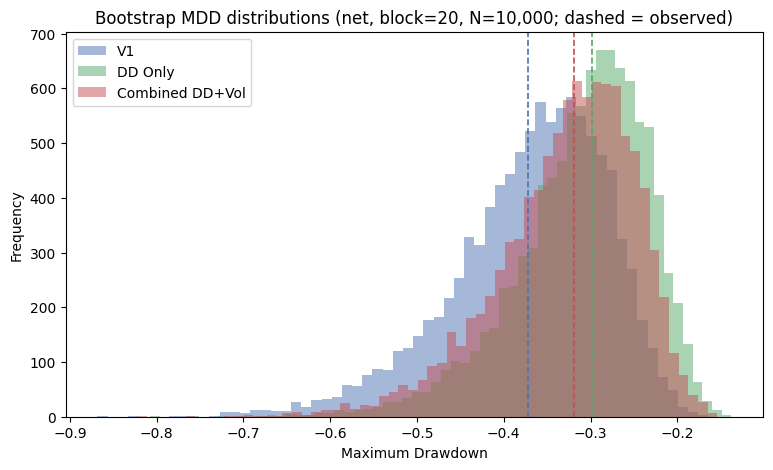

In [17]:
# One minimal figure: bootstrap MDD distributions (path robustness).
fig, ax = plt.subplots(figsize=(9, 5))
colors = {"V1": "#4C72B0", "DD Only": "#55A868", "Combined DD+Vol": "#C44E52"}
for k, dist in mdd_dists.items():
    ax.hist(dist, bins=60, alpha=0.5, label=k, color=colors[k])
    ax.axvline(obs_mdd[k], color=colors[k], linestyle="--", linewidth=1.2)
ax.set_title("Bootstrap MDD distributions (net, block=20, N=10,000; dashed = observed)")
ax.set_xlabel("Maximum Drawdown"); ax.set_ylabel("Frequency"); ax.legend()
plt.show()

**Interpretation.** On net returns, both challengers have shallower observed MDD than V1 (V1 −0.372; DD Only −0.299; Combined −0.319). The **paired** ΔMDD test is decisive for **DD Only** (p ≈ 0.0001, the add-one floor, across every block length; survives **Bonferroni and BH**). **Combined DD+Vol is marginal** — its p straddles 0.05 (≈0.042–0.062 across blocks, canonical ≈0.050): it passes **BH** but **fails Bonferroni**, and its 95% ΔMDD CI includes 0. Path-robustness agrees: DD Only has the lowest tail risk (P(MDD<−30%) ≈ 0.49 vs V1 ≈ 0.78; P(worse than V1's observed) ≈ 0.18), Combined is intermediate. All MDD inference is conditional on the block-based scheme; the block sensitivity is reported above. Kept strictly separate from the Sharpe family. No winner is selected.

In [18]:
# Augment persisted evidence records with the net MDD family (separate from Sharpe).
_ev = json.loads((EXP07 / "evidence_records.json").read_text())
for _r in _ev["records"]:
    if _r["strategy_version"] in CHAL:
        _r["extra"]["net_family_MDD_improvement"] = mdd_famA[_r["strategy_version"]]
(EXP07 / "evidence_records.json").write_text(json.dumps(_ev, indent=2))
print("evidence_records.json augmented with net MDD family for:", CHAL)

evidence_records.json augmented with net MDD family for: ['DD Only', 'Combined DD+Vol']


## CAGR Uncertainty & Robustness

Is the challengers' higher observed **net** CAGR versus V1 statistically supported, respecting serial dependence?

**Statistical caution.** CAGR is a **nonlinear** transform of terminal compounded wealth (`E_T^{252/T}-1`). IID resampling is inappropriate when serial dependence matters, so we reuse the **paired stationary block bootstrap** (shared indices for challenger and V1). All inference is **conditional on the resampling scheme** and assumed local stationarity, and a significant CAGR difference does **not** by itself imply deployability. Kept separate from the Sharpe and MDD families.

In [19]:
from src.utils.metrics import annualized_return

CAGR_SEED, CAGR_N, CAGR_BLOCKS, CAGR_CANON = 20260820, 10000, [5, 10, 20, 30, 50], 20

def cagr_from_returns(r):
    return annualized_return(pd.Series(r))   # (1+r).prod()**(252/n) - 1

# 1. Net CAGR + consistency check against the NB09 net econ table.
obs_cagr = {k: float(cagr_from_returns(net[k])) for k in net}
cagr_curve = pd.DataFrame({"net CAGR": obs_cagr,
                           "econ-table net CAGR": {k: float(econ(net[k])["CAGR"]) for k in net}})
assert np.allclose(cagr_curve["net CAGR"], cagr_curve["econ-table net CAGR"], atol=1e-12), "CAGR mismatch"
print("net CAGR consistent with NB09 econ table:", True)
cagr_curve.round(6)

net CAGR consistent with NB09 econ table: True


,net CAGR,econ-table net CAGR
V1,0.357046,0.357046
DD Only,0.388403,0.388403
Combined DD+Vol,0.405882,0.405882


### Paired ΔCAGR improvement test

H0: ΔCAGR ≤ 0  vs  H1: ΔCAGR > 0, ΔCAGR = CAGR_challenger − CAGR_V1 (positive ⇒ faster growth). Paired stationary bootstrap, N=10,000, canonical block=20, blocks [5,10,20,30,50]. One-sided **add-one** p `p = (k+1)/(N+1)` (floor `1/(N+1) ≈ 1e-4`, so no spurious `p=0`).

In [20]:
sens_rows, canon = [], {}
for ch in CHAL:
    obs_d = obs_cagr[ch] - obs_cagr["V1"]
    row = {"challenger": ch, "observed CAGR": obs_cagr[ch], "observed dCAGR": obs_d}
    for bl in CAGR_BLOCKS:
        d = paired_bootstrap_difference(net[ch].to_numpy(), net["V1"].to_numpy(),
                                        cagr_from_returns, CAGR_N, float(bl),
                                        np.random.default_rng(CAGR_SEED))
        row[f"p (block={bl})"] = (int(np.sum(d <= 0)) + 1) / (len(d) + 1)
        if bl == CAGR_CANON:
            canon[ch] = {"observed_dCAGR": obs_d, "boot_mean": float(d.mean()),
                         "boot_median": float(np.median(d)),
                         "ci_lo": float(np.percentile(d, 2.5)), "ci_hi": float(np.percentile(d, 97.5)),
                         "raw_p": (int(np.sum(d <= 0)) + 1) / (len(d) + 1)}
    sens_rows.append(row)
cagr_sensitivity = pd.DataFrame(sens_rows).set_index("challenger")
cagr_sensitivity.round(4)

,observed CAGR,observed dCAGR,p (block=5),p (block=10),p (block=20),p (block=30),p (block=50)
challenger,,,,,,,
DD Only,0.3884,0.0314,0.0169,0.0235,0.0273,0.0214,0.0209
Combined DD+Vol,0.4059,0.0488,0.0050,0.0078,0.0116,0.0179,0.0194


In [21]:
# Multiple-testing on the canonical (block=20) CAGR family (m=2), src functions.
praw = np.array([canon[c]["raw_p"] for c in CHAL])
b = bonferroni(praw, alpha=0.05); h = benjamini_hochberg(praw, alpha=0.05)
cagr_famA = {}
for i, c in enumerate(CHAL):
    cagr_famA[c] = {**canon[c], "bonferroni_adj": float(b.adjusted_pvalues[i]),
                    "bonferroni_decision": "REJECT H0" if b.rejected[i] else "fail to reject H0",
                    "bh_adj": float(h.adjusted_pvalues[i]),
                    "bh_decision": "REJECT H0" if h.rejected[i] else "fail to reject H0"}
cagr_correction_table = pd.DataFrame(cagr_famA).T[["observed_dCAGR","raw_p","bonferroni_adj",
    "bonferroni_decision","bh_adj","bh_decision"]]

sig = pd.DataFrame([{"challenger": c, "pairing": "paired (shared block indices)", "cost_bps": 10.0,
                     "m": 2, "block": CAGR_CANON, "n_boot": CAGR_N, "seed": CAGR_SEED, **cagr_famA[c]}
                    for c in CHAL])
sig.to_csv(EXP07 / "net_cagr_significance_vs_v1.csv", index=False)
print("persisted:", (EXP07 / "net_cagr_significance_vs_v1.csv").relative_to(PROJECT_ROOT))
cagr_correction_table.round(4)

persisted: experiments/completed/exp_007_candidate_net_validation/net_cagr_significance_vs_v1.csv


,observed_dCAGR,raw_p,bonferroni_adj,bonferroni_decision,bh_adj,bh_decision
DD Only,0.031357,0.027297,0.054595,fail to reject H0,0.027297,REJECT H0
Combined DD+Vol,0.048836,0.011599,0.023198,REJECT H0,0.023198,REJECT H0


In [22]:
# 4. Distribution of long-run growth: block-bootstrap CAGR per candidate (block=20).
cagr_dists = {k: bootstrap_metric(net[k].to_numpy(), cagr_from_returns, CAGR_N, float(CAGR_CANON),
                                  np.random.default_rng(CAGR_SEED)) for k in net}
v1_obs_cagr = obs_cagr["V1"]
rows = []
for k, dist in cagr_dists.items():
    q = np.percentile(dist, [5, 25, 50, 75, 95])
    rows.append({"candidate": k, "median": q[2], "p5": q[0], "p25": q[1], "p75": q[3], "p95": q[4],
                 "P(CAGR<0)": float(np.mean(dist < 0.0)),
                 "P(CAGR<V1 obs)": float(np.mean(dist < v1_obs_cagr))})
cagr_robustness = pd.DataFrame(rows).set_index("candidate")
# No project-standard downside CAGR threshold exists; report P(<0) and P(<V1 obs) only.
cagr_robustness.round(4)

,median,p5,p25,p75,p95,P(CAGR<0),P(CAGR<V1 obs)
candidate,,,,,,,
V1,0.3566,0.1487,0.2683,0.4551,0.6181,0.0010,0.5010
DD Only,0.3871,0.1870,0.3003,0.4847,0.6447,0.0002,0.4132
Combined DD+Vol,0.4027,0.1881,0.3107,0.5103,0.6867,0.0002,0.3700


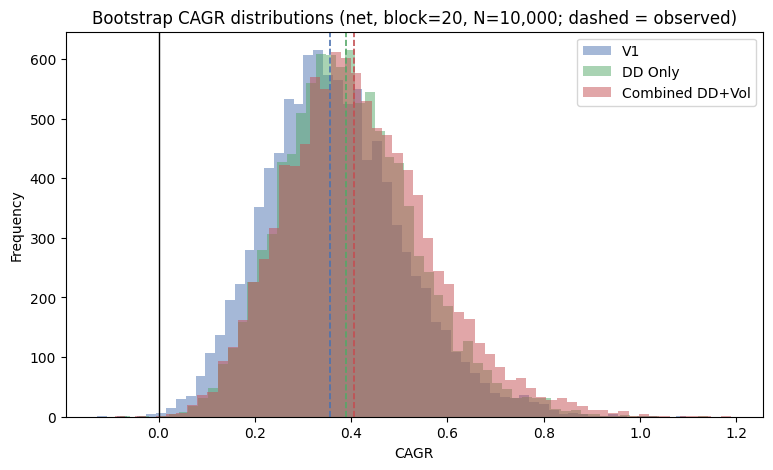

In [23]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = {"V1": "#4C72B0", "DD Only": "#55A868", "Combined DD+Vol": "#C44E52"}
for k, dist in cagr_dists.items():
    ax.hist(dist, bins=60, alpha=0.5, label=k, color=colors[k])
    ax.axvline(obs_cagr[k], color=colors[k], linestyle="--", linewidth=1.2)
ax.axvline(0.0, color="black", linewidth=1.0)
ax.set_title("Bootstrap CAGR distributions (net, block=20, N=10,000; dashed = observed)")
ax.set_xlabel("CAGR"); ax.set_ylabel("Frequency"); ax.legend()
plt.show()

**Interpretation.** On net returns both challengers grow faster than V1 (V1 0.357; DD Only 0.388; Combined 0.406). The paired ΔCAGR test is **stronger for Combined DD+Vol** (canonical p ≈ 0.012; survives **Bonferroni and BH**; 95% ΔCAGR CI excludes 0). **DD Only is borderline** — canonical p ≈ 0.027 (block band ≈ 0.017–0.027), survives **BH** but **fails Bonferroni** at m=2, and its 95% CI barely includes 0. This is the mirror image of the MDD family (where DD Only was decisive and Combined marginal): Combined trades a slightly deeper drawdown for faster compounding. Growth downside is small for all three (P(CAGR<0) ≤ ~0.1%). All inference is conditional on the block scheme; a significant CAGR gap is not, by itself, a deployment decision. No winner is selected.

In [24]:
_ev = json.loads((EXP07 / "evidence_records.json").read_text())
for _r in _ev["records"]:
    if _r["strategy_version"] in CHAL:
        _r["extra"]["net_family_CAGR_improvement"] = cagr_famA[_r["strategy_version"]]
(EXP07 / "evidence_records.json").write_text(json.dumps(_ev, indent=2))
print("evidence_records.json augmented with net CAGR family for:", CHAL)

evidence_records.json augmented with net CAGR family for: ['DD Only', 'Combined DD+Vol']


## Consolidated Net Evidence Summary

Compact synthesis of the three **separate** net hypothesis families for the two challengers (each family m=2; the six p-values are **not** pooled). Built from the already-persisted `net_{sharpe,mdd,cagr}_significance_vs_v1.csv`.

In [25]:
sh = pd.read_csv(EXP07 / "net_sharpe_significance_vs_v1.csv").set_index("challenger")
mddf = pd.read_csv(EXP07 / "net_mdd_significance_vs_v1.csv").set_index("challenger")
cg = pd.read_csv(EXP07 / "net_cagr_significance_vs_v1.csv").set_index("challenger")

notes = {
    ("DD Only", "Sharpe"): "robust; survives both", ("Combined DD+Vol", "Sharpe"): "robust; survives both",
    ("DD Only", "MDD"): "robust across blocks 5-50", ("Combined DD+Vol", "MDD"): "marginal, block-sensitive",
    ("DD Only", "CAGR"): "borderline under FWER", ("Combined DD+Vol", "CAGR"): "survives both",
}
src = {"Sharpe": (sh, "dSharpe"), "MDD": (mddf, "observed_dMDD"), "CAGR": (cg, "observed_dCAGR")}
rows = []
for ch in ["DD Only", "Combined DD+Vol"]:
    for fam, (df, eff) in src.items():
        r = df.loc[ch]
        rows.append({"challenger": ch, "family (m=2)": fam, "observed effect": float(r[eff]),
                     "raw p": float(r["raw_p"]), "Bonferroni adj": float(r["bonferroni_adj"]),
                     "BH adj": float(r["bh_adj"]), "Bonferroni": r["bonferroni_decision"],
                     "BH": r["bh_decision"], "robustness note": notes[(ch, fam)]})
evidence_summary = pd.DataFrame(rows).set_index(["challenger", "family (m=2)"])
evidence_summary.round(4)

observed effect   raw p  Bonferroni adj  BH adj  \
challenger      family (m=2)                                                    
DD Only         Sharpe                 0.2647  0.0004          0.0008  0.0008   
                MDD                    0.0729  0.0001          0.0002  0.0002   
                CAGR                   0.0314  0.0273          0.0546  0.0273   
Combined DD+Vol Sharpe                 0.1966  0.0112          0.0224  0.0112   
                MDD                    0.0527  0.0499          0.0998  0.0499   
                CAGR                   0.0488  0.0116          0.0232  0.0232   

                                     Bonferroni         BH  \
challenger      family (m=2)                                 
DD Only         Sharpe                REJECT H0  REJECT H0   
                MDD                   REJECT H0  REJECT H0   
                CAGR          fail to reject H0  REJECT H0   
Combined DD+Vol Sharpe                REJECT H0  REJECT H0   
                MDD           fail to reject H0  REJECT H0   
                CAGR                  REJECT H0  REJECT H0   

                                        robustness note  
challenger      family (m=2)                             
DD Only         Sharpe            robust; survives both  
                MDD           robust across blocks 5-50  
                CAGR              borderline under FWER  
Combined DD+Vol Sharpe            robust; survives both  
                MDD           marginal, block-sensitive  
                CAGR                      survives both

### Evidence synthesis (no strategy selection)

- **Both challengers show statistically supported net Sharpe improvement over V1** (survive Bonferroni and BH in the Sharpe family).
- **DD Only has the stronger evidence on drawdown reduction** (MDD improvement robust across all tested block lengths; survives both corrections), while its CAGR edge is borderline under family-wise correction.
- **Combined DD+Vol has the stronger evidence on CAGR improvement** (survives both corrections), while its MDD improvement is marginal and block-length-sensitive.
- **Therefore neither challenger is universally dominant** from these three metrics alone. The three families are kept separate; the six p-values are not pooled. No winner is selected.

The consolidated per-family results are already persisted in `evidence_records.json` (fields `net_family_A_sharpe_improvement`, `net_family_MDD_improvement`, `net_family_CAGR_improvement`) and the three family CSVs; no duplicate summary file is created.

## 7. Status

**Notebook 09 (Candidate Net Validation) — COMPLETE** if all cells execute cleanly. Persisted artifacts in `exp_007_candidate_net_validation/`: three `*_daily_returns.csv`, `config.json`, `evidence_records.json`, plus `net_mdd_significance_vs_v1.csv` and the MDD and CAGR significance/robustness sections, plus `net_cagr_significance_vs_v1.csv`. NB05 unchanged.